# Estimating entropy from finite samples

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`. Nearest-neighbor tie-breaking jitter also uses saved Xoshiro draws. All simulated inputs and encoded messages are retained so the calculations can be repeated across languages.

Shannon entropy is the probability-weighted average surprise of a discrete symbol, measured in bits:

$$
H(X)=-\sum_{x\in\mathcal A}p(x)\log_2 p(x),
\qquad
0\leq H(X)\leq\log_2|\mathcal A|.
$$

Here, $X$ is a discrete random variable; $\mathcal A$ is its alphabet; $x$ is one possible symbol. $p(x)$ is the probability of $x$; $H(X)$ is entropy; $|\mathcal A|$ is alphabet size; $\log_2$ uses base two.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("09_dependence_geometry_information");
using CSV, Printf
using RiskLabAI.Data: calculate_distance,calculate_mutual_information,calculate_number_of_bins,calculate_variation_of_information,calculate_variation_of_information_extended,distance_correlation,ksg_mutual_information
using RiskLabAI.Features: shannon_entropy,probability_mass_function,plug_in_entropy_estimator,lempel_ziv_entropy,kontoyiannis_entropy,miller_madow_entropy,grassberger_entropy,nsb_entropy
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute_close = raw.close
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
return_values,return_index = diff(log_price),close_index[2:end]
violet = "#C084FC"

function contingency_counts(x,y,bins)
    xedges,yedges = collect(range(extrema(x)...;length=bins+1)),collect(range(extrema(y)...;length=bins+1))
    counts = zeros(Int,bins,bins)
    for (left,right) in zip(x,y)
        counts[min(searchsortedlast(xedges,left),bins),min(searchsortedlast(yedges,right),bins)] += 1
    end
    return counts
end

function histogram_information(counts)
    probability = counts./sum(counts)
    marginal_x,marginal_y = vec(sum(probability;dims=2)),vec(sum(probability;dims=1))
    entropy(values) = -sum(value*log(value) for value in values if value>0)
    entropy_x,entropy_y,joint = entropy(marginal_x),entropy(marginal_y),entropy(probability)
    information = sum(probability[left,right]*log(probability[left,right]/(marginal_x[left]*marginal_y[right])) for left in axes(counts,1),right in axes(counts,2) if probability[left,right]>0)
    variation = entropy_x+entropy_y-2information
    return (information=information,joint=joint,variation=variation,normalized_mi=information/min(entropy_x,entropy_y),normalized_vi=variation/joint)
end


histogram_information (generic function with 1 method)

## Encoding Public Returns

In [2]:
function tercile_message(values)
    ranks = invperm(sortperm(values;alg=MergeSort))
    boundaries = quantile(collect(1:length(values)),[1/3,2/3])
    return String(['L','M','H'][[1+count(boundary->rank>boundary,boundaries) for rank in ranks]])
end
direction_message = join(ifelse.(return_values.>=0.,"U","D"))
return_state_message = tercile_message(return_values)
volatility_state_message = tercile_message(abs.(return_values))
messages = [("Return direction",direction_message),("Return tercile",return_state_message),("Absolute-return tercile",volatility_state_message)]
entropy_rows,ngram_rows,rolling_rows,pmf_rows = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
for (label,message) in messages
    push!(entropy_rows,(encoding=label,symbols=length(Set(message)),length=length(message),shannon=shannon_entropy(message),plugin=plug_in_entropy_estimator(message,2),lempel=lempel_ziv_entropy(message),kontoyiannis=kontoyiannis_entropy(message;window=64)))
end
entropy_public_summary = DataFrame(entropy_rows)
rename!(entropy_public_summary,["Encoding","Symbols","Message length","Shannon entropy","Plug-in entropy for pairs","Lempel-Ziv dictionary rate","Kontoyiannis entropy with window 64"])
for word_length in 1:6
    pmf = probability_mass_function(direction_message,word_length)
    push!(ngram_rows,(length=word_length,observed=length(pmf),possible=2^word_length,share=length(pmf)/2^word_length,plugin=plug_in_entropy_estimator(direction_message,word_length)))
    for (word,probability) in sort(collect(pmf);by=first)
        push!(pmf_rows,(word_length=word_length,word=word,probability=probability))
    end
end
ngram_summary = DataFrame(ngram_rows)
rename!(ngram_summary,["Word length","Observed words","Possible binary words","Observed share","Plug-in entropy per symbol"])
window,step = 512,128
for ending in window:step:length(direction_message)
    segment = direction_message[ending-window+1:ending]
    push!(rolling_rows,(ending=return_index[ending],observations=window,plugin=plug_in_entropy_estimator(segment,2),kontoyiannis=kontoyiannis_entropy(segment;window=64)))
end
rolling_entropy = DataFrame(rolling_rows)
summary_values(values) = [first(values),minimum(values),median(values),mean(values),maximum(values),last(values)]
entropy_window_summary = DataFrame("Summary"=>["First","Smallest","Middle value","Mean","Largest","Last"],"Plug-in entropy for pairs"=>summary_values(rolling_entropy.plugin),"Kontoyiannis entropy with window 64"=>summary_values(rolling_entropy.kontoyiannis))
save_table(entropy_public_summary,paths,"entropy_public_summary";caption="Entropy and compression measures for three encodings of public returns.",label="tab:chapter8-entropy-public")
save_table(ngram_summary,paths,"ngram_summary";caption="Observed binary words and plug-in entropy by word length.",label="tab:chapter8-ngram-summary")
save_table(entropy_window_summary,paths,"entropy_window_summary";caption="Rolling entropy summaries for the public direction message.",label="tab:chapter8-entropy-window")
save_data(DataFrame(time=return_index,return_value=return_values,direction=collect(direction_message),return_tercile=collect(return_state_message),absolute_tercile=collect(volatility_state_message)),paths,"public_encodings")
save_data(DataFrame(pmf_rows),paths,"direction_word_probabilities")
save_data(rolling_entropy,paths,"rolling_entropy");


Row,Encoding,Symbols,Message length,Shannon entropy,Plug-in entropy for pairs,Lempel-Ziv dictionary rate,Kontoyiannis entropy with window 64
,String,Int64,Int64,Float64,Float64,Float64,Float64
1,Return direction,2,2975,0.999998,0.999449,0.142185,0.856762
2,Return tercile,3,2975,1.58496,1.58133,0.190924,1.2911
3,Absolute-return tercile,3,2975,1.58496,1.57873,0.189244,1.28008


Row,Word length,Observed words,Possible binary words,Observed share,Plug-in entropy per symbol
,Int64,Int64,Int64,Float64,Float64
1,1,2,2,1.0,0.999998
2,2,4,4,1.0,0.999449
3,3,8,8,1.0,0.998681
4,4,16,16,1.0,0.997607
5,5,32,32,1.0,0.996863
6,6,64,64,1.0,0.995449


Row,Summary,Plug-in entropy for pairs,Kontoyiannis entropy with window 64
,String,Float64,Float64
1,First,0.993822,0.85955
2,Smallest,0.993822,0.833796
3,Middle value,0.998514,0.867681
4,Mean,0.998287,0.866505
5,Largest,0.999774,0.904302
6,Last,0.997598,0.867961


## Estimating entropy from compression

The plug-in estimate uses observed word frequencies, while the Lempel-Ziv rate records how many new substrings appear per symbol:

$$
\widehat H_{N,w}
=-\frac{1}{w}\sum_{a\in\mathcal A^w}\widehat p_w(a)\log_2\widehat p_w(a),
\qquad
C_{\mathrm{LZ}}=\frac{|\mathcal D_{\mathrm{LZ}}|}{N}.
$$

Here, $N$ is message length; $w$ is word length; $\mathcal A^w$ is the set of possible length-$w$ words. $\widehat p_w(a)$ is the observed frequency of word $a$; $\mathcal D_{\mathrm{LZ}}$ is the parsed substring dictionary; $|\cdot|$ counts elements.

The Kontoyiannis calculation assigns more entropy when new substrings remain short relative to the available history:

$$
\widehat H_{\mathrm K}
=\frac{1}{|\mathcal I|}\sum_{i\in\mathcal I}\frac{\log_2 n_i}{L_i},
\qquad
L_i=1+\max\{\ell:\text{the length-}\ell\text{ word at }i\text{ appears in the preceding }n_i\text{ symbols}\}.
$$

Here, $\mathcal I$ is the set of evaluated positions; $i$ is one position; $n_i$ is its look-back length. $L_i$ is one plus the longest preceding match length; $\ell$ is a candidate match length; $\widehat H_{\mathrm K}$ is the estimated entropy rate.

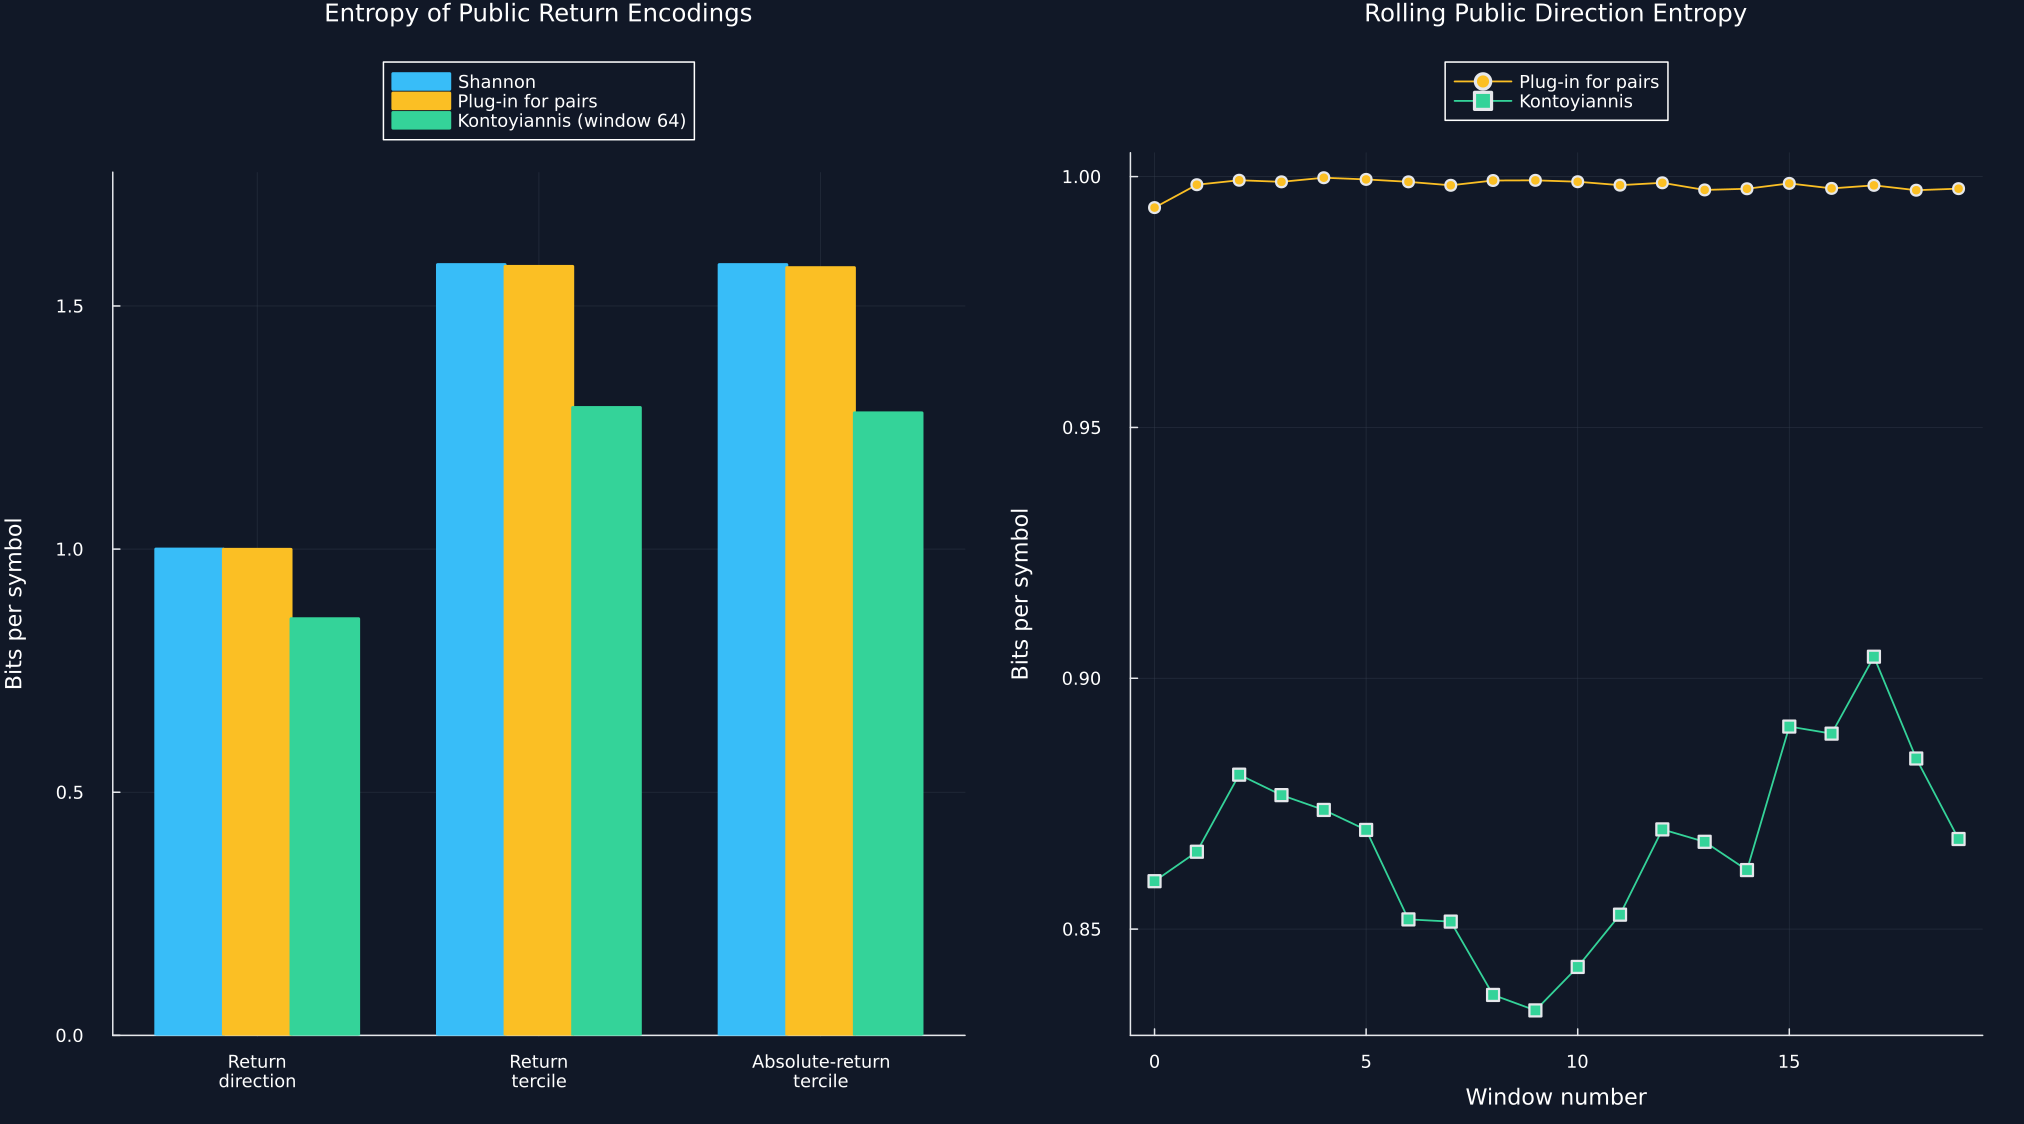

In [3]:
p1 = plot(;title="Entropy of Public Return Encodings",ylabel="Bits per symbol",xticks=(1:3,["Return
direction","Return
tercile","Absolute-return
tercile"]),legend=:outertop,legend_column=1)
for (offset,column,color,label) in [(-.24,"Shannon entropy",palette.cyan,"Shannon"),(0.,"Plug-in entropy for pairs",palette.amber,"Plug-in for pairs"),(.24,"Kontoyiannis entropy with window 64",palette.green,"Kontoyiannis (window 64)")]
    bar!(p1,(1:3).+offset,entropy_public_summary[!,column];bar_width=.24,color,linecolor=color,label)
end
ylims!(p1,0.,1.12maximum(Matrix(entropy_public_summary[:,[4,5,7]])))
p2 = plot(0:nrow(rolling_entropy)-1,rolling_entropy.plugin;color=palette.amber,marker=:circle,linewidth=1.2,label="Plug-in for pairs",title="Rolling Public Direction Entropy",xlabel="Window number",ylabel="Bits per symbol",legend=:outertop,legend_column=1)
plot!(p2,0:nrow(rolling_entropy)-1,rolling_entropy.kontoyiannis;color=palette.green,marker=:square,linewidth=1.2,label="Kontoyiannis")
save_figure(plot(p1,p2;layout=(1,2),size=(1350,750)),paths,"public_entropy_comparison")


## Finite Samples with Known Truth

A sample cannot display more distinct symbols than its size, so the plug-in estimate has a strict ceiling when the true alphabet is larger than the sample:

$$
\widehat H_N\leq\log_2\!\bigl(\min\{K,N\}\bigr),
\qquad
H_{\mathrm{uniform}}=\log_2 K.
$$

Here, $\widehat H_N$ is plug-in entropy from $N$ observations; $K$ is the true alphabet size. $H_{\mathrm{uniform}}$ is the true entropy of equally likely symbols; $\min\{K,N\}$ is the smaller of alphabet and sample size.

Row,Sample size,True entropy,Mean plug-in estimate,Estimated bias,Root mean squared error,Maximum possible sample estimate
,Int64,Float64,Float64,Float64,Float64,Float64
1,8,4.0,2.59179,-1.40821,1.42801,3.0
2,12,4.0,2.98306,-1.01694,1.04006,3.58496
3,16,4.0,3.21085,-0.789146,0.816586,4.0
4,24,4.0,3.47168,-0.528325,0.549632,4.0
5,40,4.0,3.69777,-0.302228,0.318832,4.0
6,80,4.0,3.85831,-0.141687,0.150977,4.0
7,160,4.0,3.92769,-0.0723148,0.0769475,4.0
8,320,4.0,3.96623,-0.0337734,0.0357929,4.0
9,640,4.0,3.98208,-0.0179181,0.0188009,4.0


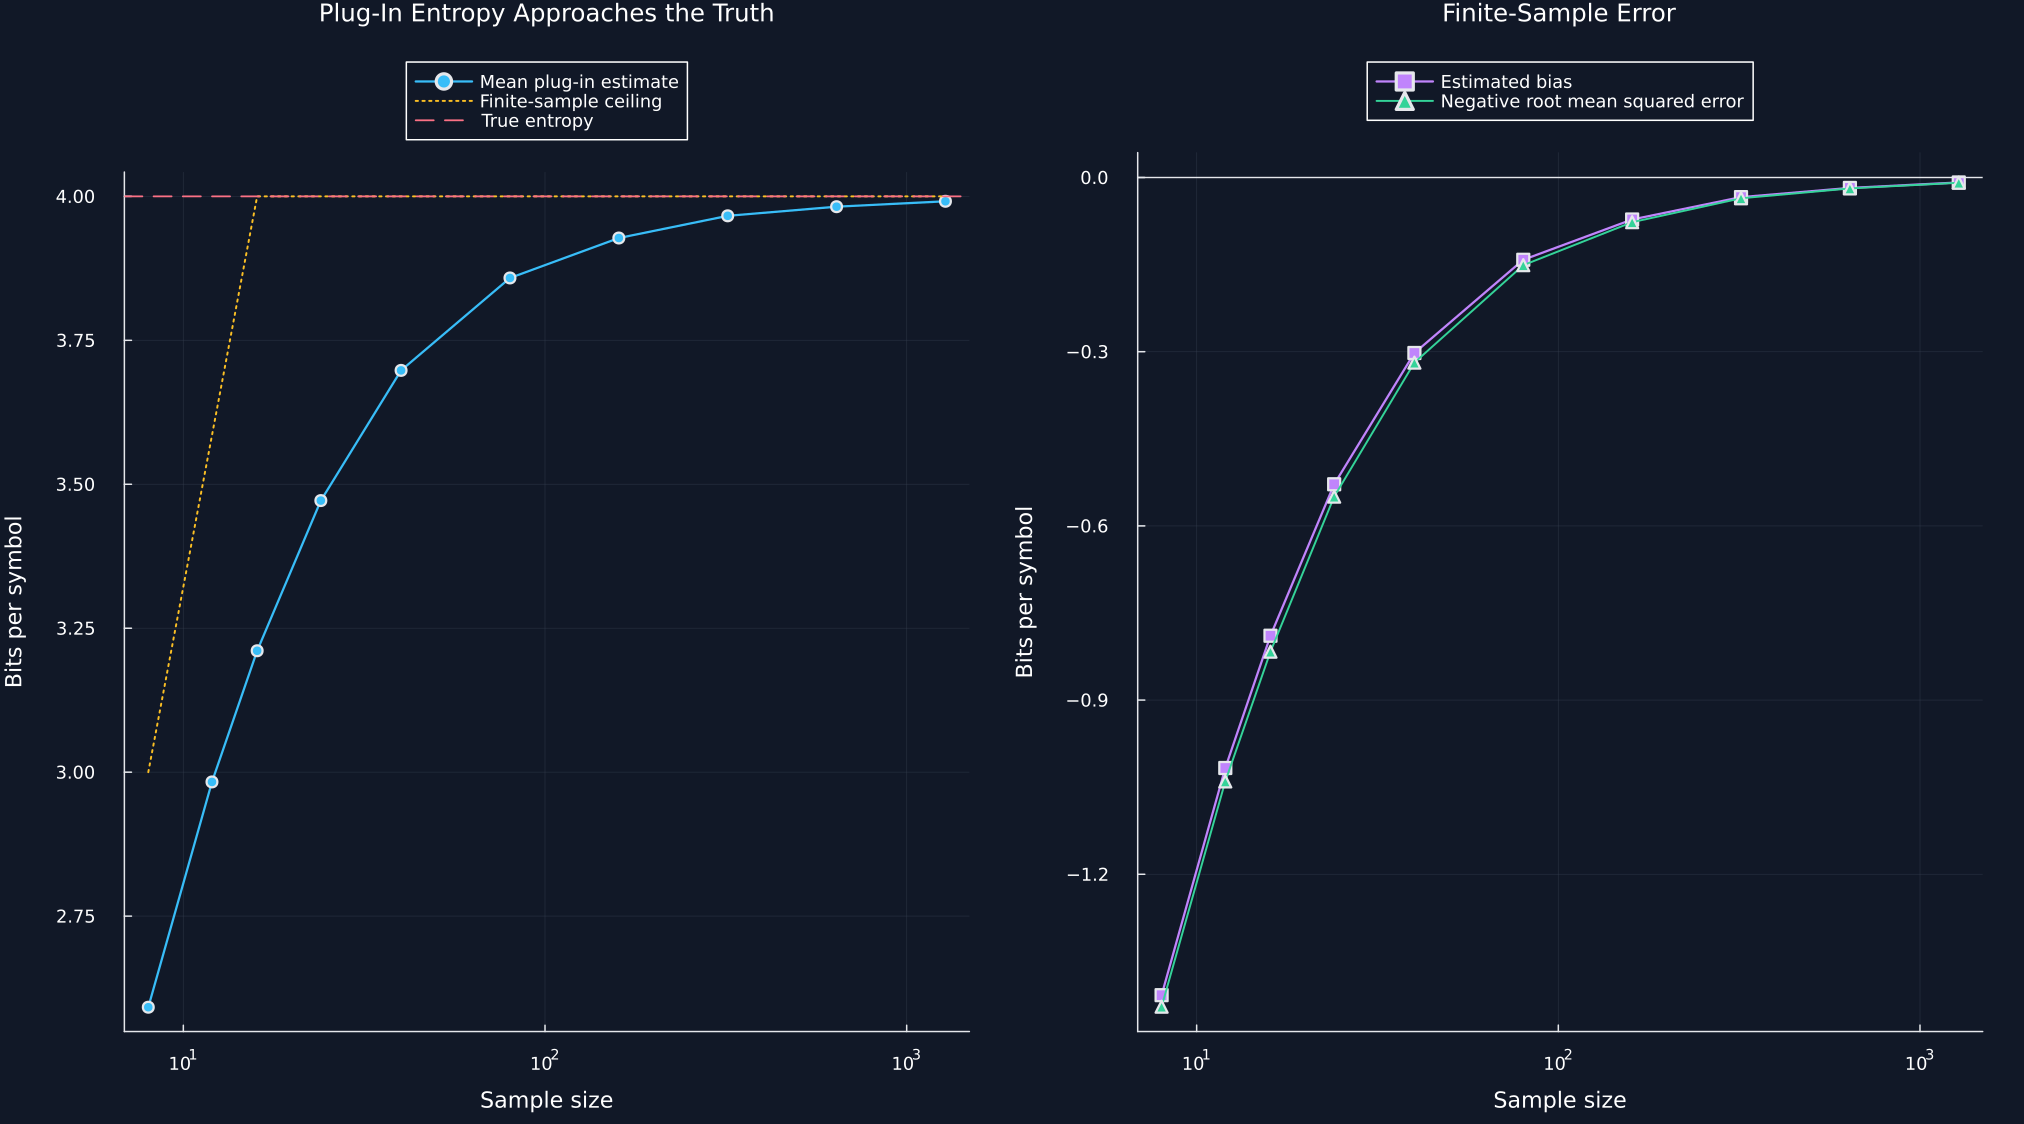

In [4]:
alphabet_size = 16
alphabet = collect("0123456789ABCDEF")
true_entropy = log2(alphabet_size)
simulation_rows,plugin_messages = NamedTuple[],NamedTuple[]
stored_estimates = Dict{Int,Vector{Float64}}()
for sample_size in [8,12,16,24,40,80,160,320,640,1280]
    estimates = Float64[]
    for repetition in 0:199
        seed = 8000+1000sample_size+repetition
        message = String(rand(Xoshiro(seed),alphabet,sample_size))
        estimate = plug_in_entropy_estimator(message,1)
        push!(estimates,estimate)
        push!(plugin_messages,(sample_size=sample_size,repetition=repetition,seed=seed,message=message,estimate=estimate))
    end
    stored_estimates[sample_size] = estimates
    push!(simulation_rows,(size=sample_size,truth=true_entropy,mean=mean(estimates),bias=mean(estimates)-true_entropy,rmse=sqrt(mean((estimates.-true_entropy).^2)),ceiling=log2(min(alphabet_size,sample_size))))
end
plugin_bias_summary = DataFrame(simulation_rows)
rename!(plugin_bias_summary,["Sample size","True entropy","Mean plug-in estimate","Estimated bias","Root mean squared error","Maximum possible sample estimate"])
save_table(plugin_bias_summary,paths,"plugin_bias_summary";caption="Plug-in entropy error for simulated uniform symbols with known truth.",label="tab:chapter8-plugin-bias")
save_data(DataFrame(plugin_messages),paths,"plugin_simulation_messages")
p1 = plot(plugin_bias_summary[!,"Sample size"],plugin_bias_summary[!,"Mean plug-in estimate"];color=palette.cyan,marker=:circle,linewidth=1.5,label="Mean plug-in estimate",xscale=:log10,title="Plug-In Entropy Approaches the Truth",xlabel="Sample size",ylabel="Bits per symbol",legend=:outertop,legend_column=1)
plot!(p1,plugin_bias_summary[!,"Sample size"],plugin_bias_summary[!,"Maximum possible sample estimate"];color=palette.amber,linestyle=:dot,linewidth=1.3,label="Finite-sample ceiling")
hline!(p1,[true_entropy];color=palette.rose,linestyle=:dash,linewidth=1.2,label="True entropy")
p2 = plot(plugin_bias_summary[!,"Sample size"],plugin_bias_summary[!,"Estimated bias"];color=violet,marker=:square,linewidth=1.5,label="Estimated bias",xscale=:log10,title="Finite-Sample Error",xlabel="Sample size",ylabel="Bits per symbol",legend=:outertop,legend_column=1)
plot!(p2,plugin_bias_summary[!,"Sample size"],-plugin_bias_summary[!,"Root mean squared error"];color=palette.green,marker=:utriangle,linewidth=1.3,label="Negative root mean squared error")
hline!(p2,[0.];color=palette.text,linewidth=.9,label=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1350,750)),paths,"plugin_entropy_bias")


## Bias Corrections for Sparse Counts

The Miller-Madow estimate adds a first correction for symbols that a short sample may miss:

$$
\widehat H_{\mathrm{MM}}
=\widehat H_{\mathrm{plug}}
+\frac{\widehat K-1}{2N\ln 2}.
$$

Here, $\widehat H_{\mathrm{MM}}$ is the corrected entropy in bits; $\widehat H_{\mathrm{plug}}$ is the observed-frequency estimate. $\widehat K$ is the number of observed symbols; $N$ is the number of observations; $\ln 2$ converts natural-log units to bits.

Row,Sample size,Method,True entropy,Mean estimate,Estimated bias,Root mean squared error
,Int64,String,Float64,Float64,Float64,Float64
1,40,Plug-in,4.0,3.67831,-0.321691,0.334525
2,40,Miller-Madow,4.0,3.92327,-0.0767329,0.129118
3,40,Grassberger,4.0,3.99357,-0.00643086,0.143144
4,40,NSB,4.0,3.84414,-0.15586,0.160867
5,80,Plug-in,4.0,3.85148,-0.148524,0.158299
6,80,Miller-Madow,4.0,3.98523,-0.0147743,0.0589906
7,80,Grassberger,4.0,4.00606,0.00606468,0.0554455
8,80,NSB,4.0,3.90927,-0.0907258,0.0939398
9,160,Plug-in,4.0,3.92175,-0.0782492,0.0825969


Row,Sample size,Method,True entropy,Mean estimate,Absolute bias
,Int64,String,Float64,Float64,Float64
1,40,Plug-in,1.0,0.982098,0.0179015
2,40,Miller-Madow,1.0,1.00013,0.000132177
3,40,Grassberger,1.0,1.01847,0.0184688
4,40,NSB,1.0,0.969761,0.0302394
5,200,Plug-in,1.0,0.997075,0.00292527
6,200,Miller-Madow,1.0,1.00068,0.000681467
7,200,Grassberger,1.0,1.0043,0.0043002
8,200,NSB,1.0,0.993806,0.00619408


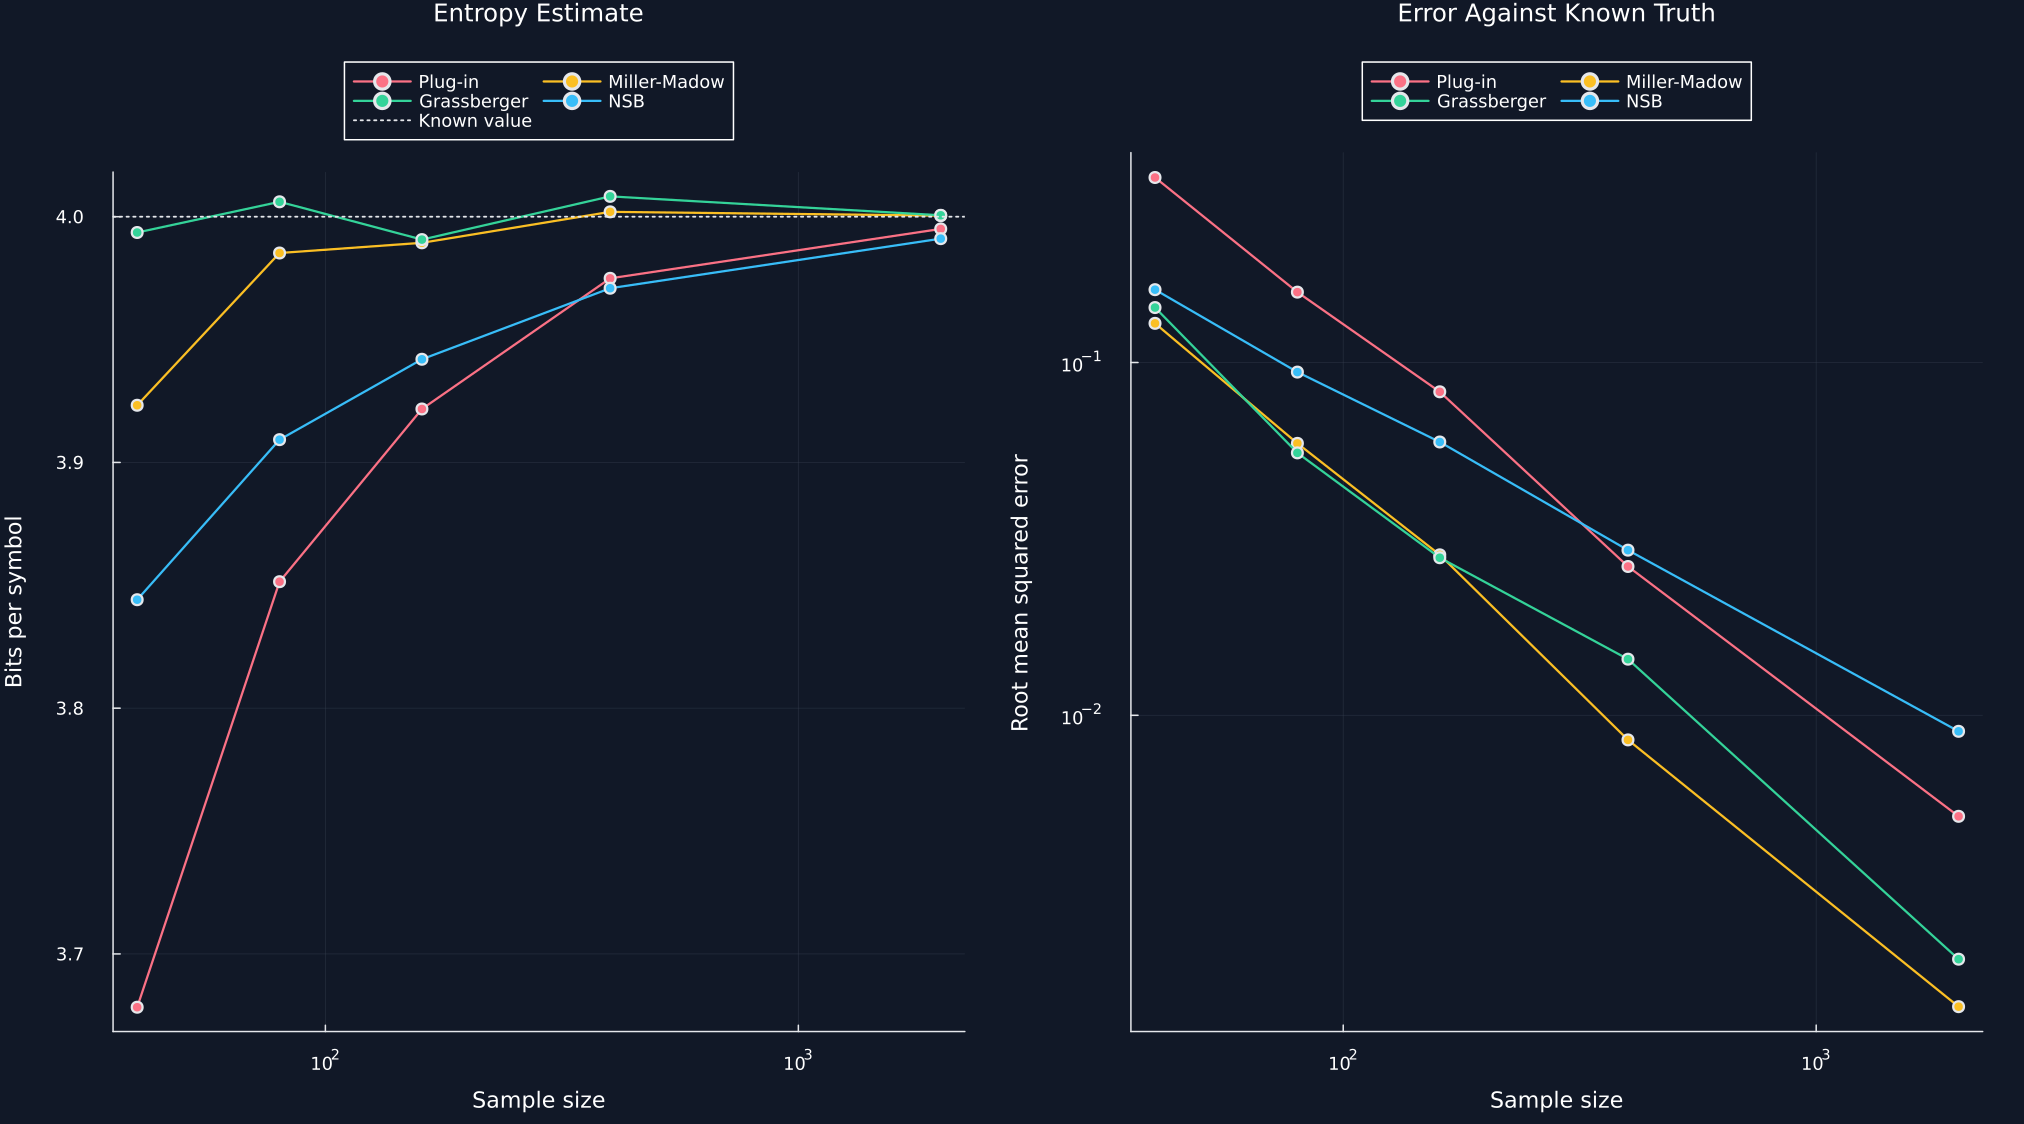

In [5]:
function random_uniform_message(symbol_count,message_length,seed)
    available_symbols = collect("0123456789abcdefghijklmnopqrstuvwxyz")[1:symbol_count]
    return String(rand(Xoshiro(seed),available_symbols,message_length))
end
corrected_sample_sizes = [40,80,160,400,2000]
corrected_methods = [("Plug-in",(message,count)->plug_in_entropy_estimator(message,1)),("Miller-Madow",(message,count)->miller_madow_entropy(message,1)),("Grassberger",(message,count)->grassberger_entropy(message,1)),("NSB",(message,count)->nsb_entropy(message,1,count))]
corrected_runs,corrected_messages,binary_runs = NamedTuple[],NamedTuple[],NamedTuple[]
for sample_size in corrected_sample_sizes,seed in 0:11
    message = random_uniform_message(alphabet_size,sample_size,seed)
    push!(corrected_messages,(alphabet=alphabet_size,sample_size=sample_size,seed=seed,message=message))
    for (method,estimator) in corrected_methods
        estimate = estimator(message,alphabet_size)
        push!(corrected_runs,(size=sample_size,seed=seed,method=method,estimate=estimate,error=estimate-true_entropy))
    end
end
bias_corrected_runs = DataFrame(corrected_runs)
corrected_rows = NamedTuple[]
for group in groupby(bias_corrected_runs,[:size,:method];sort=false)
    push!(corrected_rows,(size=group.size[1],method=group.method[1],truth=true_entropy,mean=mean(group.estimate),bias=mean(group.error),rmse=sqrt(mean(group.error.^2))))
end
bias_corrected_summary = DataFrame(corrected_rows)
rename!(bias_corrected_summary,["Sample size","Method","True entropy","Mean estimate","Estimated bias","Root mean squared error"])
for sample_size in [40,200],seed in 0:11
    message = random_uniform_message(2,sample_size,seed)
    push!(corrected_messages,(alphabet=2,sample_size=sample_size,seed=seed,message=message))
    for (method,estimator) in corrected_methods
        estimate = estimator(message,2)
        push!(binary_runs,(size=sample_size,seed=seed,method=method,estimate=estimate,error=estimate-1.))
    end
end
binary_frame = DataFrame(binary_runs)
binary_rows = NamedTuple[]
for group in groupby(binary_frame,[:size,:method];sort=false)
    push!(binary_rows,(size=group.size[1],method=group.method[1],truth=1.,mean=mean(group.estimate),bias=abs(mean(group.estimate)-1.)))
end
coarse_alphabet_summary = DataFrame(binary_rows)
rename!(coarse_alphabet_summary,["Sample size","Method","True entropy","Mean estimate","Absolute bias"])
save_table(bias_corrected_summary,paths,"bias_corrected_entropy";caption="Four entropy estimates for a sixteen-symbol source with known truth.",label="tab:chapter8-bias-corrected-entropy")
save_table(coarse_alphabet_summary,paths,"coarse_alphabet_entropy";caption="Entropy estimates for a two-symbol source with known truth.",label="tab:chapter8-coarse-alphabet-entropy")
save_data(DataFrame(corrected_messages),paths,"corrected_entropy_messages")
save_data(bias_corrected_runs,paths,"bias_corrected_runs")
save_data(binary_frame,paths,"binary_entropy_runs")
p1 = plot(;title="Entropy Estimate",xlabel="Sample size",ylabel="Bits per symbol",xscale=:log10,legend=:outertop,legend_column=2)
p2 = plot(;title="Error Against Known Truth",xlabel="Sample size",ylabel="Root mean squared error",xscale=:log10,yscale=:log10,legend=:outertop,legend_column=2)
for (method,color) in [("Plug-in",palette.rose),("Miller-Madow",palette.amber),("Grassberger",palette.green),("NSB",palette.cyan)]
    current = bias_corrected_summary[bias_corrected_summary.Method.==method,:]
    plot!(p1,current[!,"Sample size"],current[!,"Mean estimate"];color,marker=:circle,linewidth=1.5,label=method)
    plot!(p2,current[!,"Sample size"],current[!,"Root mean squared error"];color,marker=:circle,linewidth=1.5,label=method)
end
hline!(p1,[true_entropy];color=palette.text,linestyle=:dot,linewidth=1.2,label="Known value")
save_figure(plot(p1,p2;layout=(1,2),size=(1350,750)),paths,"bias_corrected_entropy")


## Tests

In [6]:
ordered,alternating,varied = "AAAAAAAAAA","ABABABABAB","ABCDEFGHIJ"
@assert length(direction_message)==2975
@assert Set(direction_message)==Set(['D','U'])
@assert nrow(entropy_public_summary)==3
@assert nrow(ngram_summary)==6
@assert nrow(entropy_window_summary)==6
@assert iszero(shannon_entropy(ordered))
@assert isapprox(shannon_entropy(alternating),1.)
@assert isapprox(shannon_entropy(varied),log2(10))
@assert probability_mass_function(alternating,2)==Dict("AB"=>5/9,"BA"=>4/9)
@assert isapprox(plug_in_entropy_estimator(alternating,1),1.)
@assert isapprox(lempel_ziv_entropy(ordered),.4)
@assert isapprox(lempel_ziv_entropy(alternating),.5)
@assert isapprox(lempel_ziv_entropy(varied),1.)
@assert isapprox(kontoyiannis_entropy("AAAAA"),.62055;atol=1e-3)
@assert isapprox(kontoyiannis_entropy("AAAAA";window=3),.660;atol=1e-3)
@assert all(plugin_bias_summary[!,"Estimated bias"].<0.)
@assert plugin_bias_summary[end,"Mean plug-in estimate"]>plugin_bias_summary[1,"Mean plug-in estimate"]
@assert isapprox(only(unique(plugin_bias_summary[!,"True entropy"])),4.)
@assert only(plugin_bias_summary[plugin_bias_summary[!,"Sample size"].==8,"Maximum possible sample estimate"])==3.
short_corrected = bias_corrected_summary[bias_corrected_summary[!,"Sample size"].==40,:]
long_corrected = bias_corrected_summary[bias_corrected_summary[!,"Sample size"].==2000,:]
short_estimates = Dict(zip(short_corrected.Method,short_corrected[!,"Mean estimate"]))
@assert Set(bias_corrected_summary.Method)==Set(first.(corrected_methods))
@assert nrow(bias_corrected_runs)==240
@assert short_estimates["Miller-Madow"]>short_estimates["Plug-in"]
@assert short_estimates["Grassberger"]>short_estimates["Plug-in"]
@assert short_estimates["NSB"]>short_estimates["Plug-in"]
@assert maximum(abs.(long_corrected[!,"Estimated bias"]))<.05
@assert maximum(coarse_alphabet_summary[!,"Absolute bias"])<.05
@assert isfile(joinpath(paths.figures,"public_entropy_comparison.pdf"))
@assert isfile(joinpath(paths.figures,"plugin_entropy_bias.pdf"))
@assert isfile(joinpath(paths.figures,"bias_corrected_entropy.pdf"))
@assert isfile(joinpath(paths.tables,"bias_corrected_entropy.tex"))
@assert isfile(joinpath(paths.tables,"coarse_alphabet_entropy.tex"))
